## Deceptive Detection

### Introduction

The rising influence of user-generated online reviews has led to growing incentive for businesses to
solicit and manufacture DECEPTIVE OPINION SPAM - fictitious reviews that have been deliberately written
to sound authentic and deceive the reader. Ott el al.(2011) have introduced an opinion spam dataset containing
gold standard deceptive 'positive' hotel reviews. However, the complementary problem of 'negative' deceptive
opinion spam, intended to slander competitive offerings, remains largely unstudied. 


In the following dataset, reviews are of four different categories. Positive and Negative reviews and in each case deceptive and non-deceptive reviews.

### Problem Statement

Classification of reviews in the form of Positive True Review, Positive Deceptive Review, Negative True Review and Negative Deceptive Review.

### Overview of the Dataset

The corpus consists of truthful and deceptive hotel reviews of 20 Chicago hotels. 

Corpus contains:-
    
* 400 truthful positive reviews from TripAdvisor
* 400 deceptive positive reviews from Mechanical Turk
* 400 truthful negative reviews from Expedia, Hotels.com, Orbitz, Priceline,
  TripAdvisor and Yelp 
* 400 deceptive negative reviews from Mechanical Turk 

Each of the above datasets consist of 20 reviews for each of the 20 most popular Chicago hotels. 
Files are named according to the format '%c_%h_%i.txt', where:
    
1. %c denotes the class : (t)ruthful or (d)eceptive
2. %h denoted the hotel


* affinia: Affinia Chicago (now MileNorth, A Chicago Hotel)
* allegro: Hotel Allegro Chicago - a Kimpton Hotel
* amalfi: Amalfi Hotel Chicago
* ambassador: Ambassador East Hotel (now PUBLIC Chicago)
* conrad: Conrad Chicago
* fairmont: Fairmont Chicago Millennium Park
* hardrock: Hard Rock Hotel Chicago
* hilton: Hilton Chicago
* homewood: Homewood Suites by Hilton Chicago Downtown
* hyatt: Hyatt Regency Chicago
* intercontinental: InterContinental Chicago
* james: James Chicago
* knickerbocker: Millennium Knickerbocker Hotel Chicago
* monaco: Hotel Monaco Chicago - a Kimpton Hotel
* omni: Omni Chicago Hotel
* palmer: The Palmer House Hilton
* sheraton: Sheraton Chicago Hotel and Towers
* sofitel: Sofitel Chicago Water Tower
* swissotel: Swissotel Chicago
* talbott: The Talbott Hotel
    
    
3. %i serves as a counter to make the filename unique


In [1]:
# Importing relevant libaries
import pandas as pd
pd.set_option('display.max_columns',100) # Displaying max columns present in the dataframe
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore') # remove warnings from the notebook
warnings.simplefilter(action='ignore', category = FutureWarning)
warnings.simplefilter(action='ignore', category = DeprecationWarning)
warnings.simplefilter(action='ignore', category = UserWarning)
import glob
import nltk
import spacy
from nltk.corpus import RegexpTokenizer as regexptoken
from sklearn.feature_extraction.text import TfidfVectorizer

In [2]:
# reading names of hotels into a list
hotels = ['affinia','allegro','amalfi','ambassador','conrad','fairmont','hardrock','hilton','homewood','hyatt','intercontinental','james','knickerbocker','monaco','omni','palmer','sheraton','sofitel','swissotel','talbott']

In [3]:
# Creating a dataframe which stores both positive and negative reviews of a list
positive_reviews = pd.DataFrame()
negative_reviews = pd.DataFrame()

In [4]:
# Accessing data for Positive True Reviews
path = (r'Deception Spam Detection\deception spam detection dataset\op_spam_v1.4\pos_tru\*.txt')
files = glob.glob(path)

In [5]:
pos_true_reviews = list()
for name in files:
    with open(name) as f:
        pos_true_reviews.append(f.read())

In [6]:
positive_reviews['Positive_true_review'] = pos_true_reviews

In [7]:
# Accessing data for Positive Deceptive Reviews
path = (r'Deception Spam Detection\deception spam detection dataset\op_spam_v1.4\pos_dec\*.txt')
files = glob.glob(path)

In [8]:
pos_dec_reviews = list()
for name in files:
    with open(name) as f:
        pos_dec_reviews.append(f.read())

In [9]:
positive_reviews['Positive_decept_review'] = pos_dec_reviews

In [10]:
positive_reviews.head()

,Positive_true_review,Positive_decept_review
0,I was completely blown away by this hotel. It ...,"After recent week stay at the Affinia Hotels, ..."
1,We've just returned from a two night stay at t...,"Although much too overpriced in my opinion, th..."
2,"Excellent location, feels like a boutique hote...",The Affinia hotel in Chicago was superb. the r...
3,"I travel a lot for business and quite frankly,...",THIS HOTEL IS FANTASTIC. I stayed there on my ...
4,We visited for my 40th birthday. We had never ...,The Affinia Chicago is a wonderful place to st...


In [11]:
# Accessing data for Negative True Review
path = (r'Deception Spam Detection\deception spam detection dataset\op_spam_v1.4\neg_tru\*.txt')
files = glob.glob(path)

In [12]:
neg_tru_review = list()
for name in files:
    with open(name) as f:
        neg_tru_review.append(f.read())

In [13]:
negative_reviews['Negative_true_review'] = neg_tru_review

In [14]:
# Accessing data for Negative Deceptive review
path = (r'Deception Detection\Deception Spam Detection\deception spam detection dataset\op_spam_v1.4\neg_dec\*.txt')
files = glob.glob(path)

In [15]:
neg_dec_review = list()
for name in files:
    with open(name) as f:
        neg_dec_review.append(f.read())

In [16]:
negative_reviews['Negative_decept_review'] = neg_dec_review

In [17]:
negative_reviews.head()

,Negative_true_review,Negative_decept_review
0,We stayed 2 nights over spring break in what w...,Affinia Chicago is one of the worst hotels I h...
1,Stayed at the Fitzpatrick as a result of all o...,I recently stayed at the Affina Chicago hotel ...
2,We booked this hotel as a last minute vacation...,I stayed at the Affina Chicago for my annivers...
3,This hotel is a shambles-furniture literally f...,If you are looking for a high end hotel on the...
4,The hotel itself was beautiful and wonderful s...,I just returned from a long weekend in Chicago...


Creating dataframes for "Positive Review" and "Negative Review" with columns 'reviews' and 'labels'

In [18]:
# Creating another dataframe which includes 'reviews' and 'labels'
positive_rev_labels = pd.DataFrame(columns=['reviews','labels'])
positive_rev_labels['reviews'] = list(positive_reviews.Positive_true_review) + list(positive_reviews.Positive_decept_review)
positive_rev_labels['labels'] = (['True']*400) + (['Deceptive']*400)
positive_rev_labels.head()

,reviews,labels
0,I was completely blown away by this hotel. It ...,True
1,We've just returned from a two night stay at t...,True
2,"Excellent location, feels like a boutique hote...",True
3,"I travel a lot for business and quite frankly,...",True
4,We visited for my 40th birthday. We had never ...,True


In [19]:
negative_rev_labels = pd.DataFrame(columns=['reviews','labels'])
negative_rev_labels['reviews'] = list(negative_reviews.Negative_true_review) + list(negative_reviews.Negative_decept_review)
negative_rev_labels['labels'] = (['True']*400) + (['Deceptive']*400)
negative_rev_labels.head()

,reviews,labels
0,We stayed 2 nights over spring break in what w...,True
1,Stayed at the Fitzpatrick as a result of all o...,True
2,We booked this hotel as a last minute vacation...,True
3,This hotel is a shambles-furniture literally f...,True
4,The hotel itself was beautiful and wonderful s...,True


#### Text Preprocessing

Converting the column "reviews" to lowercase

In [20]:
positive_rev_labels['reviews'] = positive_rev_labels['reviews'].apply(lambda x: " ".join(x.lower() for x in x.split())) 

In [21]:
negative_rev_labels['reviews'] = negative_rev_labels['reviews'].apply(lambda x: " ".join(x.lower() for x in x.split()))

We observe words such as "We've" so it would be better if we expand such words to "We have" using contractions.

In [22]:
contractions = { 
"ain't": "am not / are not / is not / has not / have not",
"aren't": "are not / am not",
"can't": "cannot",
"can't've": "cannot have",
"'cause": "because",
"could've": "could have",
"couldn't": "could not",
"couldn't've": "could not have",
"didn't": "did not",
"doesn't": "does not",
"don't": "do not",
"hadn't": "had not",
"hadn't've": "had not have",
"hasn't": "has not",
"haven't": "have not",
"he'd": "he had / he would",
"he'd've": "he would have",
"he'll": "he shall / he will",
"he'll've": "he shall have / he will have",
"he's": "he has / he is",
"how'd": "how did",
"how'd'y": "how do you",
"how'll": "how will",
"how's": "how has / how is / how does",
"I'd": "I had / I would",
"I'd've": "I would have",
"I'll": "I shall / I will",
"I'll've": "I shall have / I will have",
"I'm": "I am",
"I've": "I have",
"isn't": "is not",
"it'd": "it had / it would",
"it'd've": "it would have",
"it'll": "it shall / it will",
"it'll've": "it shall have / it will have",
"it's": "it has / it is",
"let's": "let us",
"ma'am": "madam",
"mayn't": "may not",
"might've": "might have",
"mightn't": "might not",
"mightn't've": "might not have",
"must've": "must have",
"mustn't": "must not",
"mustn't've": "must not have",
"needn't": "need not",
"needn't've": "need not have",
"o'clock": "of the clock",
"oughtn't": "ought not",
"oughtn't've": "ought not have",
"shan't": "shall not",
"sha'n't": "shall not",
"shan't've": "shall not have",
"she'd": "she had / she would",
"she'd've": "she would have",
"she'll": "she shall / she will",
"she'll've": "she shall have / she will have",
"she's": "she has / she is",
"should've": "should have",
"shouldn't": "should not",
"shouldn't've": "should not have",
"so've": "so have",
"so's": "so as / so is",
"that'd": "that would / that had",
"that'd've": "that would have",
"that's": "that has / that is",
"there'd": "there had / there would",
"there'd've": "there would have",
"there's": "there has / there is",
"they'd": "they had / they would",
"they'd've": "they would have",
"they'll": "they shall / they will",
"they'll've": "they shall have / they will have",
"they're": "they are",
"they've": "they have",
"to've": "to have",
"wasn't": "was not",
"we'd": "we had / we would",
"we'd've": "we would have",
"we'll": "we will",
"we'll've": "we will have",
"we're": "we are",
"we've": "we have",
"weren't": "were not",
"what'll": "what shall / what will",
"what'll've": "what shall have / what will have",
"what're": "what are",
"what's": "what has / what is",
"what've": "what have",
"when's": "when has / when is",
"when've": "when have",
"where'd": "where did",
"where's": "where has / where is",
"where've": "where have",
"who'll": "who shall / who will",
"who'll've": "who shall have / who will have",
"who's": "who has / who is",
"who've": "who have",
"why's": "why has / why is",
"why've": "why have",
"will've": "will have",
"won't": "will not",
"won't've": "will not have",
"would've": "would have",
"wouldn't": "would not",
"wouldn't've": "would not have",
"y'all": "you all",
"y'all'd": "you all would",
"y'all'd've": "you all would have",
"y'all're": "you all are",
"y'all've": "you all have",
"you'd": "you had / you would",
"you'd've": "you would have",
"you'll": "you shall / you will",
"you'll've": "you shall have / you will have",
"you're": "you are",
"you've": "you have"
}


In [23]:
# Using Regular Expressions to match the words in the context
import re
contractions_re = re.compile('(%s)' % '|'.join(contractions.keys()))
def expand_contractions(s, contractions_dict= contractions):
    def replace(match):
        return contractions_dict[match.group(0)]
    return contractions_re.sub(replace,s)

In [24]:
# Abbrevating Positive reviews having contractions in it
positive_rev_labels['reviews_without_contractions'] = positive_rev_labels['reviews'].map(lambda x:expand_contractions(x))

In [25]:
# Abbrevating Negative reviews having contractions in it
negative_rev_labels['reviews_without_contractions'] = negative_rev_labels['reviews'].map(lambda x:expand_contractions(x))

In [26]:
# Let us try to remove the punctuations from the column 'remove_with_contractions' in dataframe 'positive_rev_labels'
positive_rev_labels['reviews_without_contractions'] = positive_rev_labels['reviews_without_contractions'].str.replace('[^\w\s]','')

In [27]:
# Removing punctuations from 'remove_with_contractions' in dataframe 'negative_rev_labels'
negative_rev_labels['reviews_without_contractions'] = negative_rev_labels['reviews_without_contractions'].str.replace('[^\w\s]','')

In [28]:
# Let us look at the mean no of words in each positive reviews
positive_rev_labels['num_wrds'] = positive_rev_labels['reviews_without_contractions'].apply(lambda x: len(x.split()))

In [29]:
# Mean no of words in negative reviews
negative_rev_labels['num_wrds'] = negative_rev_labels['reviews_without_contractions'].apply(lambda x: len(x.split()))

#### Average word length in Positive reviews

In [30]:
# Finding the word length of reviews
positive_avg_wrd_length = pd.DataFrame(positive_rev_labels['num_wrds'].groupby(positive_rev_labels['labels']).mean())

In [31]:
positive_avg_wrd_length.reset_index()

,labels,num_wrds
0,Deceptive,116.4200
1,True,123.4675


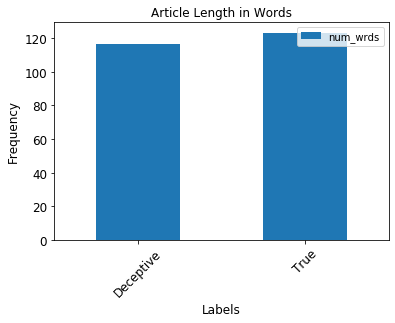

In [32]:
# Plotting the 'average word length' of 'True' and 'Deceptive' reviews
ax=positive_avg_wrd_length.plot(kind='bar', title = 'Avg Word Length of True and Deceptive Labels', figsize=(6,4), legend=True, fontsize=12)
ax.set_title("Article Length in Words", fontsize=12)
ax.set_xlabel("Labels",fontsize=12)
ax.set_ylabel("Frequency", fontsize=12);
plt.xticks(rotation=45)
plt.show()

In case of Positive Reviews, average Word Length of Truthful Review is longer than Deceptive Review .

#### Average word length in Negative Reviews

In [33]:
# Mean of words in Negative Reviews
negative_rev_labels['num_wrds'] = negative_rev_labels['reviews_without_contractions'].apply(lambda x :len(x.split()))

In [34]:
negative_avg_wrd_length = pd.DataFrame(negative_rev_labels['num_wrds'].groupby(negative_rev_labels['labels']).mean())

In [35]:
negative_avg_wrd_length.reset_index()

,labels,num_wrds
0,Deceptive,179.040
1,True,179.765


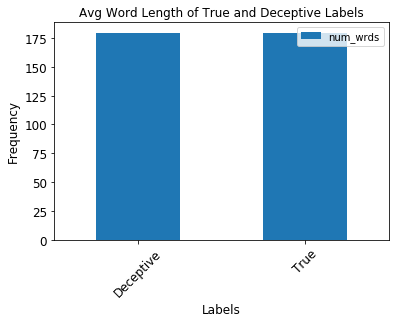

In [36]:
ax=negative_avg_wrd_length.plot(kind='bar', figsize=(6,4), legend=True, fontsize=12)
ax.set_title("Avg Word Length of True and Deceptive Labels", fontsize=12)
ax.set_xlabel("Labels",fontsize=12)
ax.set_ylabel("Frequency", fontsize=12);
plt.xticks(rotation=45)
plt.show()

In case of Negative Reviews, Average word length of Truthful Review is similar to Deceptive Review.

In [37]:
# Let us create another column which consists of unique words in the column 'reviews'
positive_rev_labels['uniq_wrds'] = positive_rev_labels['reviews_without_contractions'].str.split().apply(lambda x: len(set(x)))
positive_rev_labels.head()

,reviews,labels,reviews_without_contractions,num_wrds,uniq_wrds
0,i was completely blown away by this hotel. it ...,True,i was completely blown away by this hotel it w...,116,82
1,we've just returned from a two night stay at t...,True,we have just returned from a two night stay at...,214,130
2,"excellent location, feels like a boutique hote...",True,excellent location feels like a boutique hotel...,109,79
3,"i travel a lot for business and quite frankly,...",True,i travel a lot for business and quite frankly ...,130,87
4,we visited for my 40th birthday. we had never ...,True,we visited for my 40th birthday we had never b...,53,43


#### Average of unique words in each label


##### Unique words in Positive Reviews

In [38]:
positive_avg_uniq_wrds = pd.DataFrame(positive_rev_labels['uniq_wrds'].groupby(positive_rev_labels['labels']).mean())
positive_avg_uniq_wrds.reset_index()

,labels,uniq_wrds
0,Deceptive,76.0825
1,True,82.3225


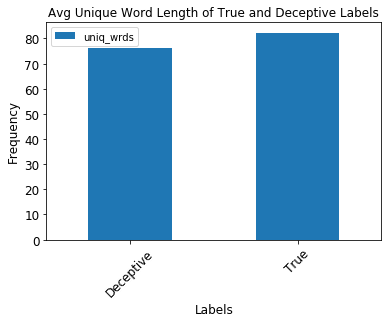

In [39]:
ax=positive_avg_uniq_wrds.plot(kind='bar', figsize=(6,4), legend=True, fontsize=12)
ax.set_title("Avg Unique Word Length of True and Deceptive Labels", fontsize=12)
ax.set_xlabel("Labels",fontsize=12)
ax.set_ylabel("Frequency", fontsize=12);
plt.xticks(rotation=45)
plt.show()

In Positive Reviews, True Labels have more unique words than Deceptive Labels.

##### Unique words in Negative Reviews

In [40]:
# Let us create another column which consists of unique words in the column 'reviews'
negative_rev_labels['uniq_wrds'] = negative_rev_labels['reviews_without_contractions'].str.split().apply(lambda x: len(set(x)))
negative_rev_labels.head()

,reviews,labels,reviews_without_contractions,num_wrds,uniq_wrds
0,we stayed 2 nights over spring break in what w...,True,we stayed 2 nights over spring break in what w...,66,51
1,stayed at the fitzpatrick as a result of all o...,True,stayed at the fitzpatrick as a result of all o...,181,106
2,we booked this hotel as a last minute vacation...,True,we booked this hotel as a last minute vacation...,115,79
3,this hotel is a shambles-furniture literally f...,True,this hotel is a shamblesfurniture literally fa...,182,117
4,the hotel itself was beautiful and wonderful s...,True,the hotel itself was beautiful and wonderful s...,130,88


In [41]:
negative_avg_uniq_wrds = pd.DataFrame(negative_rev_labels['uniq_wrds'].groupby(negative_rev_labels['labels']).mean())
negative_avg_uniq_wrds.reset_index()

,labels,uniq_wrds
0,Deceptive,106.8450
1,True,109.2425


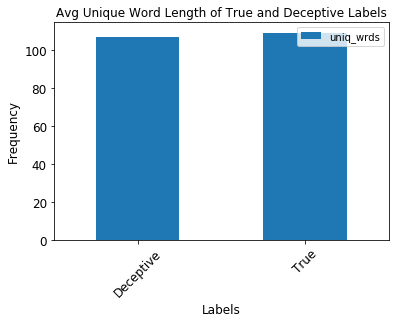

In [42]:
ax=negative_avg_uniq_wrds.plot(kind='bar', figsize=(6,4), legend=True, fontsize=12)
ax.set_title("Avg Unique Word Length of True and Deceptive Labels", fontsize=12)
ax.set_xlabel("Labels",fontsize=12)
ax.set_ylabel("Frequency", fontsize=12);
plt.xticks(rotation=45)
plt.show()

In Negative Reviews, we can observe that True Labels are having more unique words than Deceptive Labels.

#### Density of POS tags in Positive True and Positive Deceptive Reviews

In [43]:
import spacy
nlp = spacy.load('en_core_web_sm')

In [44]:
p_true_pos_tags= []
for i in range(0, 400):
    doc= nlp(positive_rev_labels.reviews_without_contractions[i])
    TAG_count = doc.count_by(spacy.attrs.TAG)
    pos_dict = dict()
    for key,value in sorted(TAG_count.items()):
        pos_dict.update({ doc.vocab[key].text : value})
    p_true_pos_tags.append(pos_dict)

In [46]:
p_dec_pos_tags = []
for i in range(400,800):
    doc = nlp(positive_rev_labels.reviews_without_contractions[i])
    TAG_count = doc.count_by(spacy.attrs.TAG)
    pos_dec_dict = dict()
    for key,value in sorted(TAG_count.items()):
        pos_dec_dict.update({ doc.vocab[key].text : value})
    p_dec_pos_tags.append(pos_dec_dict)

In [47]:
from collections import Counter
p_true_tag_count = Counter()
for i in range(0,len(p_true_pos_tags)):
    p_true_tag_count = p_true_tag_count + Counter(p_true_pos_tags[i])

In [48]:
from collections import Counter
p_dec_tag_count = Counter()
for i in range(0,len(p_dec_pos_tags)):
    p_dec_tag_count = p_dec_tag_count + Counter(p_dec_pos_tags[i])

In [49]:
p_true_tag_count = dict(p_true_tag_count)
p_dec_tag_count = dict(p_dec_tag_count)

In [50]:
positive_true_pos = pd.DataFrame()
positive_true_pos['tag'] = p_true_tag_count.keys()
positive_true_pos['true_cnt'] = p_true_tag_count.values()

In [51]:
positive_dec_pos = pd.DataFrame()
positive_dec_pos['tag'] = p_dec_tag_count.keys()
positive_dec_pos['dec_cnt'] = p_dec_tag_count.values()

In [52]:
positive_true_pos.shape

(38, 2)

In [53]:
positive_dec_pos.shape

(32, 2)

In [54]:
# We need to combine the two dataframes
positive_reviews_tags = positive_true_pos.merge(positive_dec_pos, on='tag', how='left')

In [55]:
positive_reviews_tags.head()

,tag,true_cnt,dec_cnt
0,RB,3391,3240.0
1,NNS,2135,1793.0
2,IN,5499,5111.0
3,VBG,635,689.0
4,VBN,750,689.0


In [56]:
positive_reviews_tags.shape

(38, 3)

In [57]:
positive_reviews_tags = positive_reviews_tags.set_index('tag')

In [58]:
positive_reviews_tags.head()

,true_cnt,dec_cnt
tag,,
RB,3391,3240.0
NNS,2135,1793.0
IN,5499,5111.0
VBG,635,689.0
VBN,750,689.0


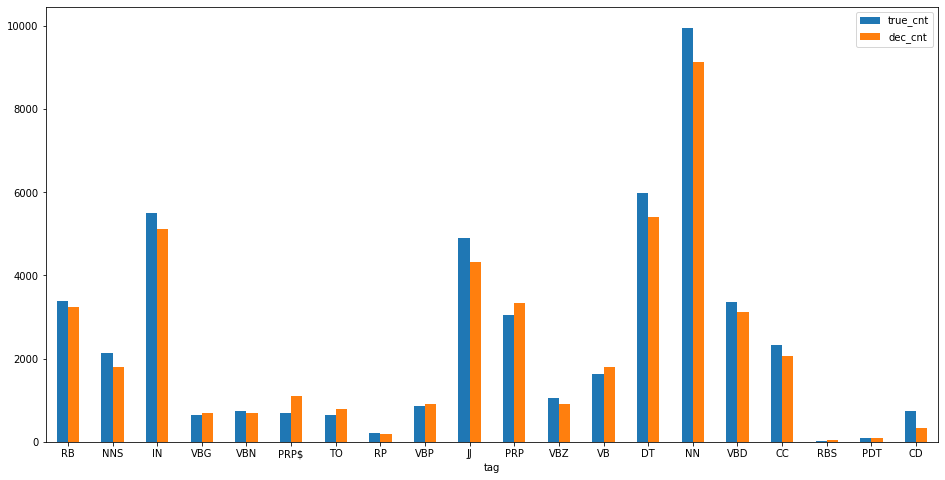

In [59]:
positive_reviews_tags[0:20].plot.bar(rot=0,figsize=(16,8))
plt.show()

Observations:-

1. Nouns are mostly used in true and deceptive reviews(hotel, chicago...)
2. Determiners are also extensively used after Nouns (this, that, would, the)
3. Words like and, but, when, or the, to, at, on are frequently used which lie under "IN" tag.

#### Density of POS tags in Negative True and Negative Deceptive Reviews

In [60]:
n_true_pos_tags = []
for i in range(0,400):
    doc = nlp(negative_rev_labels.reviews_without_contractions[i])
    TAG_count = doc.count_by(spacy.attrs.TAG)
    neg_tru_dict = dict()
    for key,value in sorted(TAG_count.items()):
        neg_tru_dict.update({doc.vocab[key].text : value})
    n_true_pos_tags.append(neg_tru_dict)
        

In [61]:
n_dec_pos_tags = []
for i in range(400,800):
    doc = nlp(negative_rev_labels.reviews_without_contractions[i])
    TAG_count = doc.count_by(spacy.attrs.TAG)
    neg_dec_dict = dict()
    for key,value in sorted(TAG_count.items()):
        neg_dec_dict.update({doc.vocab[key].text : value})
    n_dec_pos_tags.append(neg_dec_dict)

In [62]:
from collections import Counter
n_true_tag_count = Counter()
for i in range(0,len(n_true_pos_tags)):
    n_true_tag_count = n_true_tag_count + Counter(n_true_pos_tags[i])

In [63]:
from collections import Counter
n_dec_tag_count = Counter()
for i in range(0,len(n_dec_pos_tags)):
    n_dec_tag_count = n_dec_tag_count + Counter(n_dec_pos_tags[i])


In [64]:
n_true_tag_count = dict(n_true_tag_count)
n_dec_tag_count = dict(n_dec_tag_count)

In [65]:
negative_true_pos = pd.DataFrame()
negative_true_pos['tag'] = n_true_tag_count.keys()
negative_true_pos['true_cnt'] = n_true_tag_count.values()

In [66]:
negative_dec_pos = pd.DataFrame()
negative_dec_pos['tag'] = n_dec_tag_count.keys()
negative_dec_pos['dec_cnt'] = n_dec_tag_count.values()

In [67]:
negative_true_pos.shape

(36, 2)

In [68]:
negative_dec_pos.shape

(34, 2)

In [69]:
# We need to merge two dataframes
negative_review_tags = negative_true_pos.merge(negative_dec_pos, on='tag', how='left')

In [70]:
negative_review_tags = negative_review_tags.set_index('tag')

In [71]:
negative_review_tags.head()

,true_cnt,dec_cnt
tag,,
RB,5430,5576.0
NNS,2788,2455.0
IN,8055,8143.0
VBG,1173,1275.0
VBN,1633,1645.0


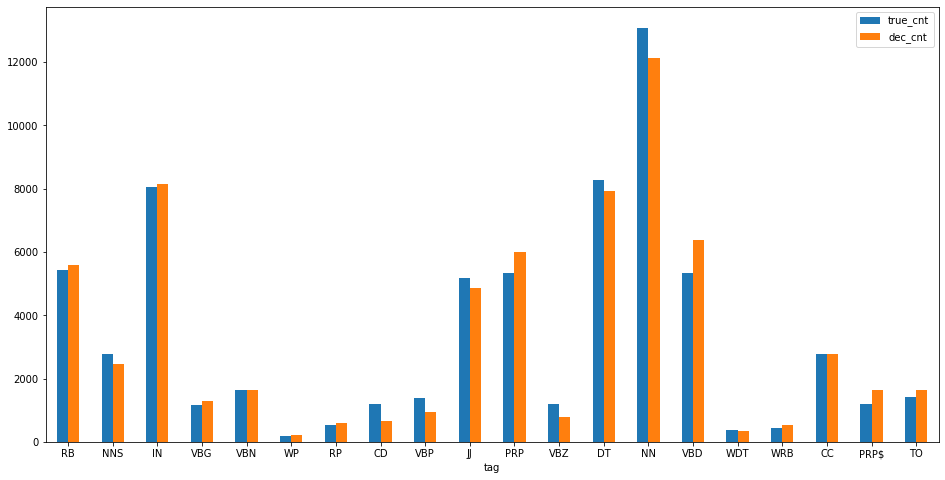

In [72]:
negative_review_tags[0:20].plot.bar(rot=0,figsize=(16,8))
plt.show()

The same observation goes with the Negative Review as well.

We will be checking for null strings in the positive reviews and negative reviews.

In [73]:
positive_rev_labels.isna().mean()

reviews                         0.0
labels                          0.0
reviews_without_contractions    0.0
num_wrds                        0.0
uniq_wrds                       0.0
dtype: float64

In [74]:
negative_rev_labels.isna().mean()

reviews                         0.0
labels                          0.0
reviews_without_contractions    0.0
num_wrds                        0.0
uniq_wrds                       0.0
dtype: float64

Inorder to find out the frequency of content words , we will be using the stopwords and extract relevant words

In [75]:
from nltk.corpus import stopwords
stop = stopwords.words('english')

In [76]:
positive_rev_labels['reviews_without_stopwords'] = positive_rev_labels['reviews_without_contractions'].apply(lambda x:" ".join([word for word in x.split() if word not in (stop) ]))

In [77]:
positive_rev_labels.head()

,reviews,labels,reviews_without_contractions,num_wrds,uniq_wrds,reviews_without_stopwords
0,i was completely blown away by this hotel. it ...,True,i was completely blown away by this hotel it w...,116,82,completely blown away hotel magnificent got gr...
1,we've just returned from a two night stay at t...,True,we have just returned from a two night stay at...,214,130,returned two night stay affinia chicago visit ...
2,"excellent location, feels like a boutique hote...",True,excellent location feels like a boutique hotel...,109,79,excellent location feels like boutique hotel r...
3,"i travel a lot for business and quite frankly,...",True,i travel a lot for business and quite frankly ...,130,87,travel lot business quite frankly expectations...
4,we visited for my 40th birthday. we had never ...,True,we visited for my 40th birthday we had never b...,53,43,visited 40th birthday never chicago sure stay ...


In [78]:
# Creating ngrams for column 'reviews' consisting of true labels
unigram_text = positive_rev_labels.reviews_without_stopwords[0:400]\
                                  .str.lower()\
                                  .str.replace('[^a-z\s]','')\
                                  .str.split(expand=True)\
                                  .stack()

# generating bigrams by concatenating unigram columns
bigram_text = unigram_text + ' ' + unigram_text.shift(-1)

# generating trigrams by concatenating unigram and bigram columns
trigram_text = bigram_text + ' ' + unigram_text.shift(-2)

ngrams_df = pd.concat([unigram_text, bigram_text, trigram_text]).dropna().reset_index(drop=True)

In [79]:
ngrams_df = pd.DataFrame(ngrams_df, columns=['ngram_text'])

In [80]:
ngrams_df.head()

,ngram_text
0,completely
1,blown
2,away
3,hotel
4,magnificent


In [81]:
# Frequency Distribution of n-grams
fdist = nltk.FreqDist(ngrams_df['ngram_text'])

In [82]:
fdist

FreqDist({'hotel': 703, 'room': 535, 'great': 401, 'chicago': 300, 'stay': 297, 'staff': 250, 'location': 214, 'stayed': 194, 'would': 193, 'rooms': 173, ...})

In [83]:
# Placing the most_common positive n-grams into a dictionary 
pos_true_freq = {}
for word, frequency in fdist.most_common(50):
    pos_true_freq[word] = frequency

In [84]:
pos_true_freq

{'hotel': 703,
 'room': 535,
 'great': 401,
 'chicago': 300,
 'stay': 297,
 'staff': 250,
 'location': 214,
 'stayed': 194,
 'would': 193,
 'rooms': 173,
 'service': 159,
 'nice': 152,
 'clean': 148,
 'us': 137,
 'night': 131,
 'friendly': 129,
 'comfortable': 127,
 'one': 123,
 'good': 122,
 'bed': 110,
 'michigan': 105,
 'also': 105,
 'helpful': 103,
 'breakfast': 99,
 'well': 98,
 'got': 95,
 'bathroom': 95,
 'excellent': 94,
 'view': 93,
 'could': 92,
 'like': 90,
 'get': 89,
 'time': 86,
 'floor': 84,
 'recommend': 82,
 'desk': 79,
 'place': 78,
 'city': 77,
 'really': 77,
 'large': 76,
 'lobby': 75,
 'wonderful': 75,
 'even': 74,
 'free': 72,
 'best': 72,
 'shopping': 71,
 'nights': 71,
 'restaurant': 70,
 'everything': 70,
 'day': 68}

In [85]:
pos_true_freq_df = pd.DataFrame(pos_true_freq.items(), columns=["n-grams","frequency"])

In [86]:
pos_true_freq_df.head(30)

,n-grams,frequency
0,hotel,703
1,room,535
2,great,401
3,chicago,300
4,stay,297
5,staff,250
6,location,214
7,stayed,194
8,would,193
9,rooms,173


We can observe that "stay" and "stayed" are similar. Likewise, "room" and "rooms" are also similar. So, using the replace option of the pandas dataframe.

In [87]:
pos_true_freq_df.replace({ 'stayed' : 'stay',
                           'room' : 'rooms'}, inplace=True)

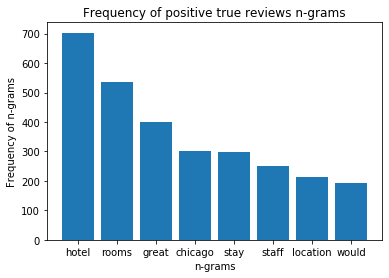

<Figure size 1152x864 with 0 Axes>

In [88]:
plt.bar(pos_true_freq_df['n-grams'][0:10], pos_true_freq_df['frequency'][0:10])
plt.xlabel('n-grams')
plt.ylabel('Frequency of n-grams')
plt.title('Frequency of positive true reviews n-grams')
plt.figure(figsize=(16,12))
plt.show()

For the Positive true reviews, the frequency of  'NN' tag is used the most followed by 'JJ' tag.

In [89]:
# Creating ngrams for column 'reviews' consisting of deceptive labels
unigram_dec_text = positive_rev_labels.reviews_without_stopwords[400:800] \
                                      .str.lower() \
                                      .str.replace('[^a-z\s]','') \
                                      .str.split(expand=True) \
                                      .stack()
  

# Generating bigrams by concatenating unigrams
bigram_dec_text = unigram_dec_text + ' ' + unigram_dec_text.shift(-1)

# Generating trigrams by concatenating unigrams, bigrams
trigram_dec_text = bigram_dec_text + ' ' + bigram_dec_text.shift(-2)

ngrams_dec_df = pd.concat([unigram_dec_text, bigram_dec_text, trigram_dec_text]).dropna().reset_index(drop=True)

In [90]:
bigram_df = nltk.FreqDist(bigram_dec_text)

In [91]:
bigram_freq = {}
for word, freq in bigram_df.most_common(50):
    bigram_freq[word] = freq
    

In [92]:
ngrams_dec_df = pd.DataFrame(ngrams_dec_df, columns=['ngram_text'])

In [93]:
ngrams_dec_df.head()

,ngram_text
0,recent
1,week
2,stay
3,affinia
4,hotels


In [94]:
pos_dec_fdist = nltk.FreqDist(ngrams_dec_df['ngram_text'])

In [95]:
pos_dec_fdist

FreqDist({'hotel': 859, 'chicago': 577, 'room': 411, 'stay': 356, 'great': 256, 'staff': 219, 'rooms': 183, 'service': 182, 'would': 177, 'stayed': 163, ...})

In [96]:
pos_dec_freq = {}
for word, freq in pos_dec_fdist.most_common(50):
    pos_dec_freq[word] = freq
    
    
    

In [97]:
pos_dec_freq

{'hotel': 859,
 'chicago': 577,
 'room': 411,
 'stay': 356,
 'great': 256,
 'staff': 219,
 'rooms': 183,
 'service': 182,
 'would': 177,
 'stayed': 163,
 'time': 146,
 'one': 127,
 'like': 125,
 'clean': 123,
 'comfortable': 118,
 'recommend': 115,
 'business': 114,
 'definitely': 112,
 'could': 112,
 'place': 111,
 'nice': 106,
 'friendly': 106,
 'city': 105,
 'also': 103,
 'best': 98,
 'beautiful': 95,
 'really': 95,
 'experience': 91,
 'wonderful': 89,
 'area': 87,
 'location': 86,
 'hotels': 85,
 'back': 84,
 'amazing': 84,
 'even': 84,
 'well': 84,
 'downtown': 83,
 'staying': 82,
 'husband': 81,
 'next': 81,
 'food': 77,
 'enjoyed': 77,
 'made': 73,
 'us': 73,
 'visit': 72,
 'ever': 71,
 'everything': 71,
 'day': 70,
 'get': 69,
 'home': 69}

In [98]:
pos_dec_freq_df = pd.DataFrame(pos_dec_freq.items(), columns=["n-grams","frequency"])

In [99]:
pos_dec_freq_df.head(10)

,n-grams,frequency
0,hotel,859
1,chicago,577
2,room,411
3,stay,356
4,great,256
5,staff,219
6,rooms,183
7,service,182
8,would,177
9,stayed,163


In this context as well, we will be replacing 'stayed' and 'rooms'.

In [100]:
pos_dec_freq_df.replace({'stayed' : 'stay',
                      'room' : 'rooms'},inplace=True)

Let us plot the graph and see the most frequent words ngrams in deceptive reviews

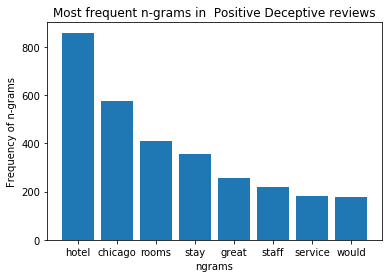

In [101]:
plt.bar(pos_dec_freq_df['n-grams'][0:10], pos_dec_freq_df['frequency'][0:10])
plt.xlabel('ngrams')
plt.ylabel('Frequency of n-grams')
plt.title('Most frequent n-grams in  Positive Deceptive reviews')
plt.show()

From the n-gram graphs of Positive true reviews and Positive deceptive reviews , we can observe words
'hotel','chicago' being most frequently in Deceptive reviews than True reviews. From this we can infer that
that since the person hasn't visited the hotel review given is mainly on a abstract basis on overall hotel, place where it is located 'Chicago' etc.

#### Finding n-grams for negative reviews[True, Deceptive] as well

In [102]:
# Let us lower the text in column 'reviews'
negative_rev_labels['reviews'] = negative_rev_labels['reviews'].apply(lambda x: " ".join(x.lower() for x in x.split())) 

In [103]:
negative_rev_labels.head()

,reviews,labels,reviews_without_contractions,num_wrds,uniq_wrds
0,we stayed 2 nights over spring break in what w...,True,we stayed 2 nights over spring break in what w...,66,51
1,stayed at the fitzpatrick as a result of all o...,True,stayed at the fitzpatrick as a result of all o...,181,106
2,we booked this hotel as a last minute vacation...,True,we booked this hotel as a last minute vacation...,115,79
3,this hotel is a shambles-furniture literally f...,True,this hotel is a shamblesfurniture literally fa...,182,117
4,the hotel itself was beautiful and wonderful s...,True,the hotel itself was beautiful and wonderful s...,130,88


In [104]:
from nltk.corpus import stopwords
stop = stopwords.words('english')

In [105]:
negative_rev_labels['reviews_without_stopwords'] = negative_rev_labels['reviews'].apply(lambda x:" ".join([word for word in x.split() if word not in (stop) ]))

In [106]:
negative_rev_labels.head()

,reviews,labels,reviews_without_contractions,num_wrds,uniq_wrds,reviews_without_stopwords
0,we stayed 2 nights over spring break in what w...,True,we stayed 2 nights over spring break in what w...,66,51,stayed 2 nights spring break called jr suite r...
1,stayed at the fitzpatrick as a result of all o...,True,stayed at the fitzpatrick as a result of all o...,181,106,stayed fitzpatrick result glowing reviews trip...
2,we booked this hotel as a last minute vacation...,True,we booked this hotel as a last minute vacation...,115,79,booked hotel last minute vacation planned litt...
3,this hotel is a shambles-furniture literally f...,True,this hotel is a shamblesfurniture literally fa...,182,117,hotel shambles-furniture literally falling apa...
4,the hotel itself was beautiful and wonderful s...,True,the hotel itself was beautiful and wonderful s...,130,88,hotel beautiful wonderful staff bottom line im...


In [107]:
# Creating ngrams for column 'reviews' consisting of true labels
neg_unigram_text = negative_rev_labels.reviews_without_stopwords[0:400]\
                                  .str.lower()\
                                  .str.replace('[^a-z\s]','')\
                                  .str.split(expand=True)\
                                  .stack()

# generating bigrams by concatenating unigram columns
neg_bigram_text = neg_unigram_text + ' ' + neg_unigram_text.shift(-1)

# generating trigrams by concatenating unigram and bigram columns
neg_trigram_text = neg_bigram_text + ' ' + neg_unigram_text.shift(-2)



In [108]:
neg_ngrams_df = pd.concat([neg_unigram_text, neg_bigram_text, neg_trigram_text]).dropna().reset_index(drop=True)

In [109]:
neg_ngrams_df = pd.DataFrame(neg_ngrams_df, columns=['ngram_text'])

In [110]:
neg_ngrams_df.head()

,ngram_text
0,stayed
1,nights
2,spring
3,break
4,called


In [111]:
neg_fdist = nltk.FreqDist(neg_ngrams_df['ngram_text'])
neg_fdist

FreqDist({'room': 844, 'hotel': 775, 'stay': 301, 'would': 263, 'one': 230, 'service': 218, 'us': 201, 'night': 199, 'get': 192, 'staff': 187, ...})

In [112]:
neg_freq = {}
for word, freq in neg_fdist.most_common(50):
    neg_freq[word] = freq

In [113]:
neg_freq

{'room': 844,
 'hotel': 775,
 'stay': 301,
 'would': 263,
 'one': 230,
 'service': 218,
 'us': 201,
 'night': 199,
 'get': 192,
 'staff': 187,
 'chicago': 183,
 'desk': 178,
 'rooms': 165,
 'bed': 159,
 'stayed': 153,
 'even': 153,
 'great': 140,
 'front': 138,
 'could': 137,
 'like': 134,
 'good': 132,
 'location': 132,
 'nice': 132,
 'never': 130,
 'called': 129,
 'time': 127,
 'bathroom': 126,
 'two': 124,
 'told': 123,
 'day': 119,
 'back': 118,
 'also': 117,
 'front desk': 116,
 'floor': 114,
 'got': 110,
 'it': 107,
 'small': 104,
 'first': 102,
 'hotels': 102,
 'go': 98,
 'lobby': 97,
 'better': 97,
 'next': 94,
 'much': 94,
 'again': 92,
 'asked': 86,
 'door': 84,
 'said': 81,
 'call': 81,
 'water': 80}

In [114]:
neg_freq_df = pd.DataFrame(neg_freq.items(), columns=["n-grams", "frequency"])

In [115]:
neg_freq_df.head(10)

,n-grams,frequency
0,room,844
1,hotel,775
2,stay,301
3,would,263
4,one,230
5,service,218
6,us,201
7,night,199
8,get,192
9,staff,187


Let us plot the graph and see the most frequent words in true reviews.

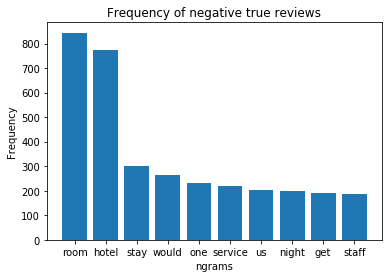

In [116]:
plt.bar(neg_freq_df['n-grams'][0:10], neg_freq_df['frequency'][0:10])
plt.xlabel('ngrams')
plt.ylabel('Frequency')
plt.title('Frequency of negative true reviews')
plt.show()

In case of Negative True reviews, Nouns, Adjectives and Verb are the most frequently used.

In [117]:
# Creating n-grams for column 'reviews' consisting of deceptive labels
neg_dec_unigram_text = negative_rev_labels.reviews_without_stopwords[400:800] \
                                      .str.lower() \
                                      .str.replace('[^a-z\s]','') \
                                      .str.split(expand=True) \
                                      .stack()

# Generating bigrams by concatenating unigram columns
neg_dec_bigram_text = neg_dec_unigram_text + ' ' + neg_dec_unigram_text.shift(-1)

# Generating trigrams by concatenating bigram columns
neg_dec_trigram_text = neg_dec_bigram_text + ' ' + neg_dec_unigram_text.shift(-2)

In [118]:
neg_dec_ngrams = pd.concat([neg_dec_unigram_text, neg_dec_bigram_text, neg_dec_trigram_text]).dropna().reset_index(drop=True)

In [119]:
neg_dec_ngrams_df = pd.DataFrame(neg_dec_ngrams , columns =['ngrams'])

In [120]:
neg_dec_ngrams_df.head()

,ngrams
0,affinia
1,chicago
2,one
3,worst
4,hotels


In [121]:
# Frequency distribution of content words
neg_dec_fdist = nltk.FreqDist(neg_dec_ngrams_df['ngrams'])
neg_dec_fdist

FreqDist({'room': 976, 'hotel': 945, 'chicago': 438, 'stay': 346, 'would': 303, 'service': 246, 'one': 223, 'like': 203, 'desk': 195, 'get': 190, ...})

In [122]:
# Placing the most common words used across Negative Deceptive reviews in a dictionary
neg_dec_dict = {}
for word, freq in neg_dec_fdist.most_common(50):
    neg_dec_dict[word] = freq
    

In [123]:
neg_dec_dict

{'room': 976,
 'hotel': 945,
 'chicago': 438,
 'stay': 346,
 'would': 303,
 'service': 246,
 'one': 223,
 'like': 203,
 'desk': 195,
 'get': 190,
 'staff': 177,
 'us': 167,
 'rooms': 166,
 'could': 163,
 'time': 160,
 'night': 158,
 'even': 155,
 'stayed': 153,
 'front': 148,
 'got': 141,
 'front desk': 138,
 'experience': 137,
 'first': 131,
 'back': 123,
 'arrived': 117,
 'went': 116,
 'finally': 114,
 'bed': 113,
 'again': 110,
 'made': 109,
 'never': 107,
 'it': 104,
 'staying': 104,
 'found': 101,
 'also': 100,
 'next': 99,
 'nice': 98,
 'check': 98,
 'seemed': 97,
 'minutes': 96,
 'place': 96,
 'bathroom': 95,
 'hotels': 93,
 'rude': 93,
 'took': 92,
 'go': 92,
 'reservation': 90,
 'good': 88,
 'better': 88,
 'another': 88}

In [124]:
neg_dec_rev_df = pd.DataFrame(neg_dec_dict.items(), columns=['ngrams', 'frequency'])

In [125]:
neg_dec_rev_df.head()

,ngrams,frequency
0,room,976
1,hotel,945
2,chicago,438
3,stay,346
4,would,303


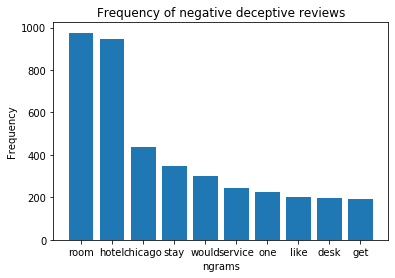

In [126]:
plt.bar(neg_dec_rev_df['ngrams'][0:10], neg_dec_rev_df['frequency'][0:10])
plt.xlabel('ngrams')
plt.ylabel('Frequency')
plt.title('Frequency of negative deceptive reviews')
plt.show()

1. Words like 'Room','Hotel' are frequently used in Negative deceptive reviews than Negative True Reviews.
2. Description of the City is more in deceptive review than true negative reviews.
3. True reviews includes more of the ambience of the hotels , we can figure out by the usage of words 'staff' , 'night' and so on...

#### Extracting relevant features with specified adjectives using TF-IDF matrix

Deceptive Reviews use lot of first-person singular use, often attributed to pyschological distancing. Let us make use of POS Tags to extract the relevant features.

In [127]:
allowed_word_types = ["PRP", "JJ", "NNP", "NNS"]
all_words = []


for p in positive_rev_labels['reviews_without_contractions']:
    tokenizer = regexptoken(r'\w+')
    words = tokenizer.tokenize(p)
    pos = nltk.pos_tag(words)
    for w in pos:
        if w[1] in allowed_word_types:
            all_words.append(w[0])
            
pos_word_final = list(set(all_words))



In [128]:
# Now TF-IDF vectorizer will form vocabulary on these words, that will form features essentially.

tfidf_vectorizer = TfidfVectorizer(ngram_range=(1,1),max_features = 5000, vocabulary = pos_word_final)
tfid = tfidf_vectorizer.fit_transform(positive_rev_labels['reviews_without_contractions'])
dense = tfid.todense()
dense.shape

(800, 2154)

In [129]:
# Transforming these features to a DataFrame
pos_df = pd.DataFrame(dense)
pos_df['Target'] = [0] * 400 + [1] * 400

In [130]:
pos_df.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,...,2105,2106,2107,2108,2109,2110,2111,2112,2113,2114,2115,2116,2117,2118,2119,2120,2121,2122,2123,2124,2125,2126,2127,2128,2129,2130,2131,2132,2133,2134,2135,2136,2137,2138,2139,2140,2141,2142,2143,2144,2145,2146,2147,2148,2149,2150,2151,2152,2153,Target
0,0.0,0.000000,0.0,0.191461,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.124626,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.081855,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.110253,0.0,0.0,0.070530,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,0.0,0.186853,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.262487,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.124967,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
3,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.119214,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
4,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


#### Model Building

In [131]:
Y = pos_df['Target']

In [132]:
pos_df = pos_df.drop(['Target'], axis=1)

In [133]:
X = pos_df

Upon fetching X and Y values, we shall use split the data into Train and Test.

In [134]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=42)


#### Logistic Regression

In [135]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(X_train,Y_train)
y_lr_pred = lr.predict(X_test)

##### Confusion matrix(Logistic)

[[86 12]
 [25 77]]


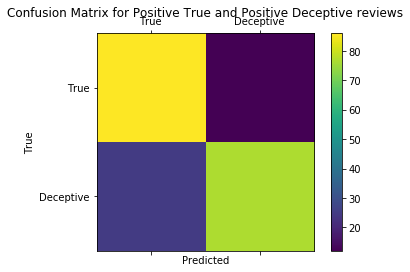

In [136]:
from sklearn.metrics import confusion_matrix
labels = ['True', 'Deceptive']
cm = confusion_matrix(Y_test,y_lr_pred,labels=[0, 1])
print(cm)
fig = plt.figure()
ax = fig.add_subplot(111)
cax = ax.matshow(cm)    # Display an array as a matrix in a new figure window
plt.title('Confusion Matrix for Positive True and Positive Deceptive reviews')
fig.colorbar(cax)
ax.set_xticklabels([''] + labels)
ax.set_yticklabels([''] + labels)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

##### Classification_report(Logistic)

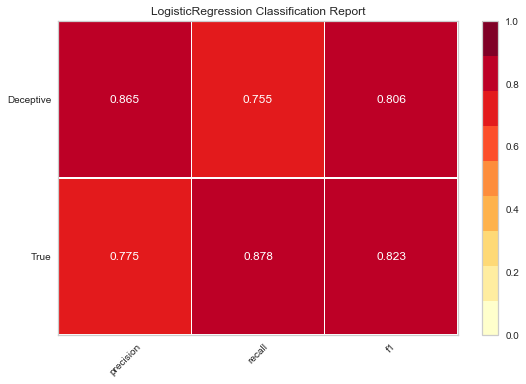

In [137]:
from yellowbrick.classifier import ClassificationReport
# Instantiating the classification model and visualizer
visualizer = ClassificationReport(lr,classes=['True', 'Deceptive'])
visualizer.fit(X_train, Y_train)
visualizer.score(X_test, Y_test)
g = visualizer.poof()

##### ROC Curve(Logistic)

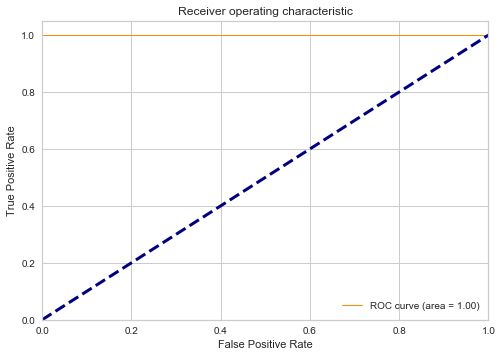

In [138]:
from sklearn.metrics import roc_curve, auc
y_pred_probs = lr.predict_proba(X_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_lr_pred, y_pred_probs)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=1, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=3, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic')
plt.legend(loc="lower right")
plt.show()

##### Accuracy_score(Logistic)

In [139]:
from sklearn.metrics import accuracy_score

In [140]:
print("Accuracy Score : ", accuracy_score(Y_test, y_lr_pred))

Accuracy Score :  0.815


#### Support Vector Machine (SVM)

In [141]:
from sklearn.svm import SVC

sv = SVC(random_state=0, kernel='linear')
sv.fit(X_train, Y_train)
y_svm_pred = sv.predict(X_test)

#### Confusion Matrix(SVM)

[[87 11]
 [26 76]]


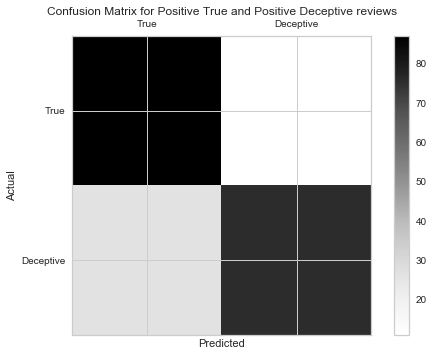

In [142]:
from sklearn.metrics import confusion_matrix
labels = ['True', 'Deceptive']
cm = confusion_matrix(Y_test,y_svm_pred,labels=[0,1])
print(cm)
fig = plt.figure()
ax = fig.add_subplot(111)
cax = ax.matshow(cm)    # Display an array as a matrix in a new figure window
plt.title('Confusion Matrix for Positive True and Positive Deceptive reviews')
fig.colorbar(cax)
ax.set_xticklabels([''] + labels)
ax.set_yticklabels([''] + labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

#### Classification Report(SVM)

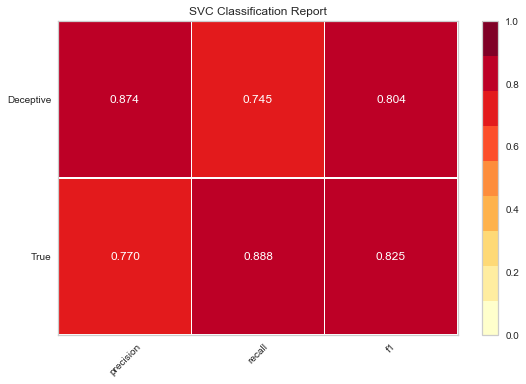

In [143]:
from yellowbrick.classifier import ClassificationReport
# Instantiating the classification model and visualizer
visualizer = ClassificationReport(sv,classes=['True', 'Deceptive'])
visualizer.fit(X_train, Y_train)
visualizer.score(X_test, Y_test)
g = visualizer.poof()

##### ROC Curve(SVM)

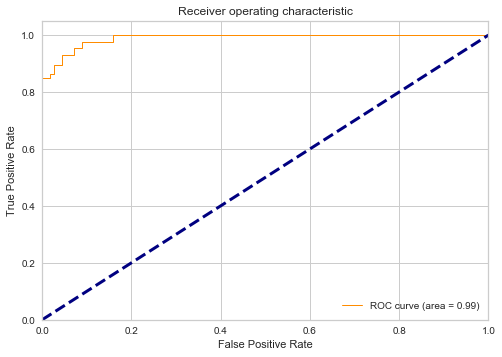

In [144]:
from sklearn.metrics import roc_curve, auc
y_pred_probs = lr.predict_proba(X_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_svm_pred, y_pred_probs)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=1, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=3, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic')
plt.legend(loc="lower right")
plt.show()

##### Accuracy Score(SVM)

In [145]:
print("Accuracy Score : ", accuracy_score(Y_test, y_svm_pred))

Accuracy Score :  0.815


#### Naive Bayes

In [146]:
from sklearn.naive_bayes import MultinomialNB  
nb = MultinomialNB()
nb.fit(X_train, Y_train)
y_nb_pred = nb.predict(X_test) 

##### Confusion Matrix(Naive Bayes)

[[86 12]
 [18 84]]


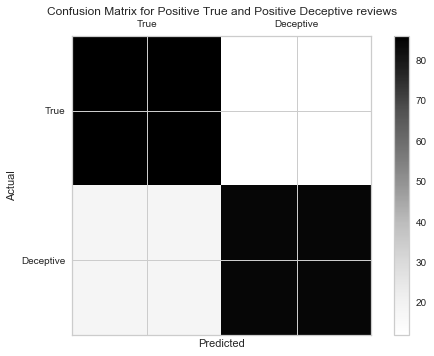

In [147]:
from sklearn.metrics import confusion_matrix
labels = ['True', 'Deceptive']
cm = confusion_matrix(Y_test,y_nb_pred,labels=[0,1])
print(cm)
fig = plt.figure()
ax = fig.add_subplot(111)
cax = ax.matshow(cm)    # Display an array as a matrix in a new figure window
plt.title('Confusion Matrix for Positive True and Positive Deceptive reviews')
fig.colorbar(cax)
ax.set_xticklabels([''] + labels)
ax.set_yticklabels([''] + labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

##### ClassificationReport(Naive Bayes)

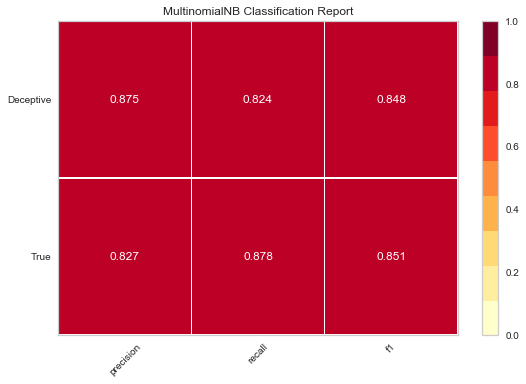

In [148]:
from yellowbrick.classifier import ClassificationReport
# Instantiating the classification model and visualizer
visualizer = ClassificationReport(nb,classes=['True', 'Deceptive'])
visualizer.fit(X_train, Y_train)
visualizer.score(X_test, Y_test)
g = visualizer.poof()

##### ROC Curve(Naive Bayes)

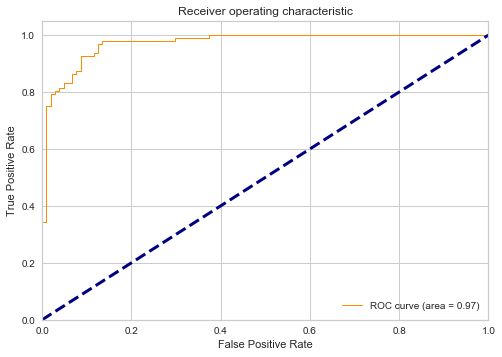

In [149]:
from sklearn.metrics import roc_curve, auc
y_pred_probs = lr.predict_proba(X_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_nb_pred, y_pred_probs)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=1, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=3, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic')
plt.legend(loc="lower right")
plt.show()

##### Accuracy Score(Naive Bayes)

In [150]:
print("Accuracy Score : ", accuracy_score(Y_test, y_nb_pred))

Accuracy Score :  0.85


#### Decision Tree

In [151]:
from sklearn.tree import DecisionTreeClassifier

dtc = DecisionTreeClassifier()
dtc.fit(X_train, Y_train)
y_dtc_pred = dtc.predict(X_test)

##### Confusion Matrix(Decision Tree)

[[77 21]
 [38 64]]


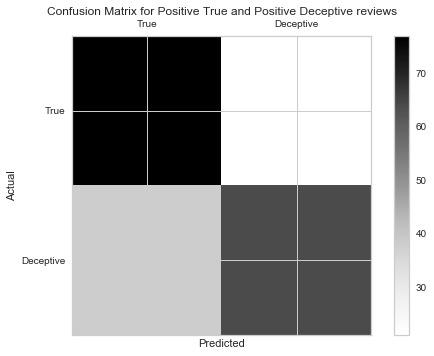

In [152]:
from sklearn.metrics import confusion_matrix
labels = ['True', 'Deceptive']
cm = confusion_matrix(Y_test,y_dtc_pred,labels=[0,1])
print(cm)
fig = plt.figure()
ax = fig.add_subplot(111)
cax = ax.matshow(cm)    # Display an array as a matrix in a new figure window
plt.title('Confusion Matrix for Positive True and Positive Deceptive reviews')
fig.colorbar(cax)
ax.set_xticklabels([''] + labels)
ax.set_yticklabels([''] + labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

##### Classification Report(Decision Tree)

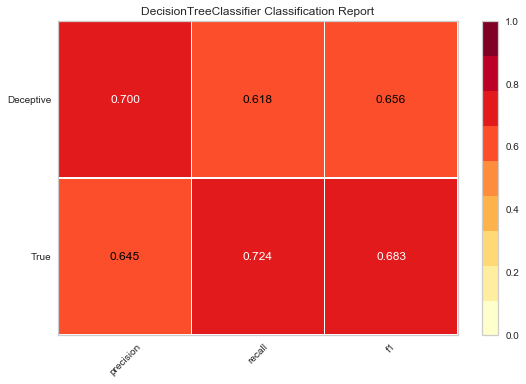

In [153]:
from yellowbrick.classifier import ClassificationReport
# Instantiating the classification model and visualizer
visualizer = ClassificationReport(dtc,classes=['True', 'Deceptive'])
visualizer.fit(X_train, Y_train)
visualizer.score(X_test, Y_test)
g = visualizer.poof()

##### ROC Curve(Decision Tree)

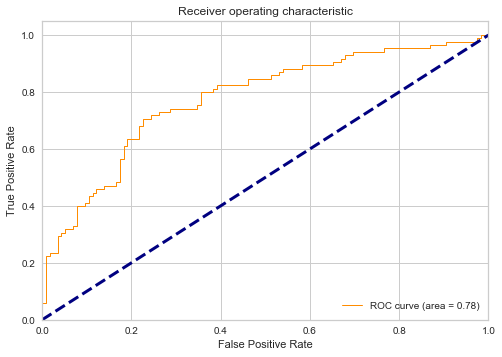

In [154]:
from sklearn.metrics import roc_curve, auc
y_pred_probs = lr.predict_proba(X_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_dtc_pred, y_pred_probs)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=1, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=3, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic')
plt.legend(loc="lower right")
plt.show()

##### Accuracy Score(Decision Tree)

In [155]:
print("Accuracy Score : ",accuracy_score(Y_test, y_dtc_pred))

Accuracy Score :  0.705


#### Random Forest

In [156]:
from sklearn.ensemble import RandomForestClassifier
rfc = RandomForestClassifier()
rfc.fit(X_train, Y_train)
y_rf_pred = rfc.predict(X_test)

##### Confusion Matrix(Random Forest)

[[72 26]
 [33 69]]


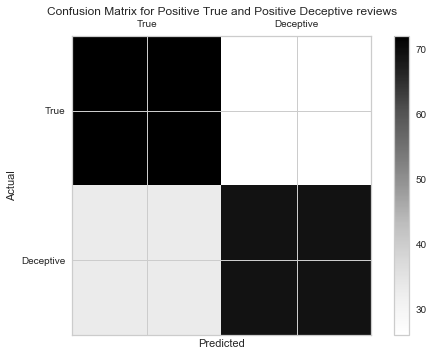

In [157]:
from sklearn.metrics import confusion_matrix
labels = ['True', 'Deceptive']
cm = confusion_matrix(Y_test,y_rf_pred,labels=[0,1])
print(cm)
fig = plt.figure()
ax = fig.add_subplot(111)
cax = ax.matshow(cm)    # Display an array as a matrix in a new figure window
plt.title('Confusion Matrix for Positive True and Positive Deceptive reviews')
fig.colorbar(cax)
ax.set_xticklabels([''] + labels)
ax.set_yticklabels([''] + labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

##### ClassificationReport(Random Forest)

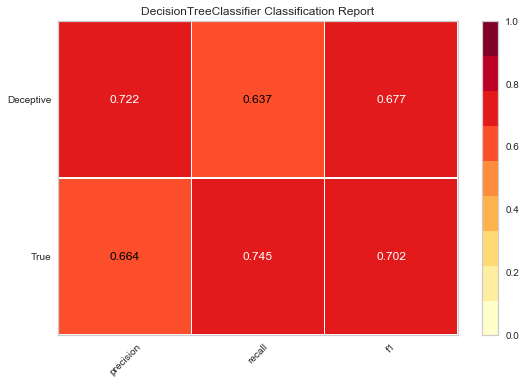

In [158]:
from yellowbrick.classifier import ClassificationReport
# Instantiating the classification model and visualizer
visualizer = ClassificationReport(dtc,classes=['True', 'Deceptive'])
visualizer.fit(X_train, Y_train)
visualizer.score(X_test, Y_test)
g = visualizer.poof()

##### ROC Curve(Random Forest)

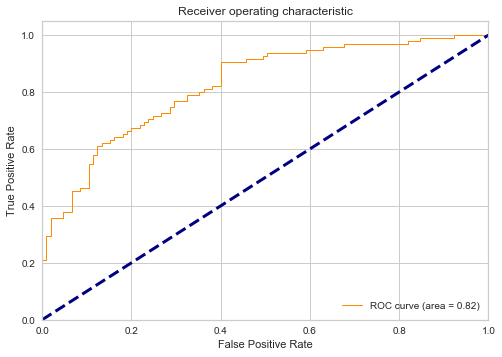

In [159]:
from sklearn.metrics import roc_curve, auc
y_pred_probs = lr.predict_proba(X_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_rf_pred, y_pred_probs)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=1, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=3, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic')
plt.legend(loc="lower right")
plt.show()

##### Accuracy Score(Random Forest)

In [160]:
print("Accuracy Score : ", accuracy_score(Y_test,y_rf_pred))

Accuracy Score :  0.705


#### XG Boost

In [161]:
import xgboost as xgb

In [162]:
xgb_model = xgb.XGBClassifier(objective="binary:logistic",random_state=42)
xgb_model.fit(X_train, Y_train)
y_xgb_pred = xgb_model.predict(X_test)

##### Confusion Matrix(XG Boost)

[[82 16]
 [29 73]]


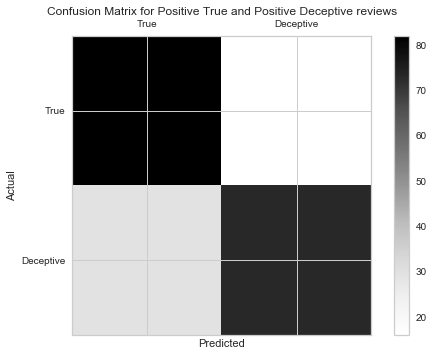

In [163]:
from sklearn.metrics import confusion_matrix
labels = ['True', 'Deceptive']
cm = confusion_matrix(Y_test,y_xgb_pred,labels=[0,1])
print(cm)
fig = plt.figure()
ax = fig.add_subplot(111)
cax = ax.matshow(cm)    # Display an array as a matrix in a new figure window
plt.title('Confusion Matrix for Positive True and Positive Deceptive reviews')
fig.colorbar(cax)
ax.set_xticklabels([''] + labels)
ax.set_yticklabels([''] + labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

##### Classification Report(XG Boost)

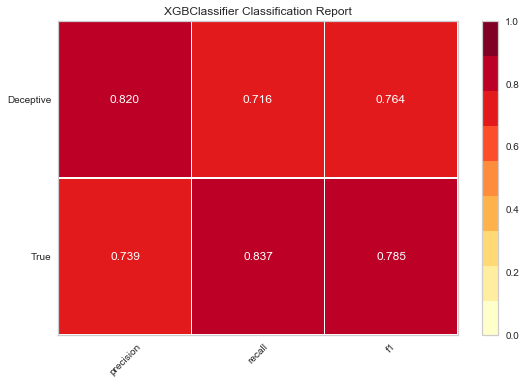

In [164]:
from yellowbrick.classifier import ClassificationReport
# Instantiating the classification model and visualizer
visualizer = ClassificationReport(xgb_model,classes=['True', 'Deceptive'])
visualizer.fit(X_train, Y_train)
visualizer.score(X_test, Y_test)
g = visualizer.poof()

##### ROC Curve(XG Boost)

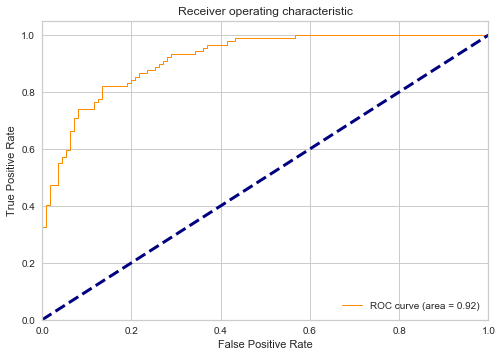

In [165]:
from sklearn.metrics import roc_curve, auc
y_pred_probs = lr.predict_proba(X_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_xgb_pred, y_pred_probs)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=1, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=3, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic')
plt.legend(loc="lower right")
plt.show()

##### Accuracy Score(XG Boost)

In [166]:
print("Accuracy Score : ", accuracy_score(Y_test, y_xgb_pred))

Accuracy Score :  0.775


#### Depicting Model Report in a DataFrame

In [167]:
import plotly.offline as py
py.init_notebook_mode(connected=True)
import plotly.figure_factory as ff

In [168]:
from sklearn.metrics import recall_score, precision_score,roc_auc_score,f1_score

In [169]:
def model_report(model, train_x, test_x, train_y, test_y, name):
    model.fit(train_x, train_y)
    predictions = model.predict(test_x)
    accuracy = accuracy_score(test_y, predictions)
    recallscore = recall_score(test_y, predictions)
    precision = precision_score(test_y, predictions)
    roc_auc = roc_auc_score(test_y, predictions)
    f1score = f1_score(test_y, predictions)
    
    model_df = pd.DataFrame({"Model" : [name],
                             "Accuracy_score" : [accuracy],
                             "Recall_score" : [recallscore],
                             "Precision" : [precision],
                             "f1_score" : [f1score],
                             "Area_under_curve" : [roc_auc]})
    return model_df




In [170]:
# Outputs for model

model1 = model_report(lr, X_train,X_test,Y_train,Y_test,"Logistic Regression" )
model2 = model_report(sv, X_train,X_test,Y_train,Y_test,"SVM")
model3 = model_report(nb, X_train,X_test,Y_train,Y_test,"Naive Bayes")

# Hyperparameter tuning
dtc = DecisionTreeClassifier(max_depth=10,
                             random_state=123,
                             splitter = 'best',
                             criterion = 'gini')
model4 = model_report(dtc,X_train,X_test,Y_train,Y_test,"Decision Tree")
rfc = RandomForestClassifier(n_estimators=2000,
                             random_state=123,
                             max_depth=10,
                             criterion="gini")
model5 = model_report(rfc,X_train,X_test,Y_train,Y_test,"Random Forest")
model6 = model_report(xgb_model, X_train, X_test, Y_train, Y_test , "XG Boost")


# concat all models
model_performances = pd.concat([model1, model2, model3, model4, model5, model6], axis=0).reset_index()
model_performances = model_performances.drop(columns="index",axis=1)

table = ff.create_table(np.round(model_performances,4))
py.iplot(table)


Table depicts that Naive Bayes , performs well in predicting the True Reviews from Deceptive Reviews.

#### Model Building for Negative Reviews

In [171]:
allowed_word_types = ["JJ","NN","NNP","NNS"]
all_neg_words = []

for wrd in negative_rev_labels["reviews_without_contractions"]:
    tokenizer = regexptoken('\w+')
    words = tokenizer.tokenize(wrd)
    pos = nltk.pos_tag(words)
    for w in pos:
        if w[1] in allowed_word_types:
            all_neg_words.append(w[0])
            
neg_words_final = list(set(all_neg_words))
    

In [172]:
# TF-IDF Vectorizer for Negative Reviews

neg_tfidf_vectorizer = TfidfVectorizer(ngram_range=(1,1),vocabulary=neg_words_final)

neg_tfidf = neg_tfidf_vectorizer.fit_transform(negative_rev_labels['reviews_without_contractions'])
neg_dense = neg_tfidf.todense()
neg_dense.shape

neg_rev_df = pd.DataFrame(neg_dense)
neg_rev_df['Target'] = [0] * 400 + [1] * 400


In [173]:
# Get the values for X and Y

Y = neg_rev_df['Target']
neg_rev_df = neg_rev_df.drop(['Target'], axis=1)
X = neg_rev_df

In [174]:

# Using K-Fold Cross validation for splitting the train and test data
from sklearn.model_selection import cross_val_score, cross_val_predict, KFold
kf = KFold(n_splits=10,shuffle=True)

#### Logistic Regression

In [175]:
scores = []
for i in range(5):
    result = next(kf.split(X),None)
    train_X = X.iloc[result[0]]
    test_X = X.iloc[result[1]]
    train_Y = Y.iloc[result[0]]
    test_Y = Y.iloc[result[1]]
    model = lr.fit(train_X,train_Y)
    cv_lr_pred = lr.predict(test_X)
    scores.append(model.score(test_X, test_Y))
print("Scores for each iteration:",scores)
print("Average K-Fold score:",np.mean(scores))

Scores for each iteration: [0.8125, 0.85, 0.825, 0.9125, 0.775]
Average K-Fold score: 0.835


#### Gaussian Naive Bayes

In [176]:
from sklearn.naive_bayes import GaussianNB
gnb = GaussianNB()
gnb.fit(X,Y)
scores = []
for i in range(5):
    result = next(kf.split(X),None)
    train_X = X.iloc[result[0]]
    test_X = X.iloc[result[1]]
    train_Y = Y.iloc[result[0]]
    test_Y = Y.iloc[result[1]]
    model = gnb.fit(train_X,train_Y)
    cv_gnb_predict = gnb.predict(test_X)
    scores.append(model.score(test_X, test_Y))
print("Scores for each iteration:",scores)
print("Average K-Fold score:",np.mean(scores))

Scores for each iteration: [0.675, 0.5375, 0.65, 0.65, 0.6375]
Average K-Fold score: 0.6299999999999999


#### SVM

In [177]:
scores = []
for i in range(5):
    result = next(kf.split(X),None)
    train_X = X.iloc[result[0]]
    test_X = X.iloc[result[1]]
    train_Y = Y.iloc[result[0]]
    test_Y = Y.iloc[result[1]]
    model = sv.fit(train_X,train_Y)
    cv_svm_predict = sv.predict(test_X)
    scores.append(model.score(test_X, test_Y))
print("Scores for each iteration:",scores)
print("Average K-Fold score:",np.mean(scores))

Scores for each iteration: [0.9125, 0.85, 0.8, 0.8375, 0.9125]
Average K-Fold score: 0.8625


#### Decision Tree

In [178]:
scores = []
for i in range(5):
    result = next(kf.split(X),None)
    train_X = X.iloc[result[0]]
    test_X = X.iloc[result[1]]
    train_Y = Y.iloc[result[0]]
    test_Y = Y.iloc[result[1]]
    model = dtc.fit(train_X,train_Y)
    cv_dtc_predict = dtc.predict(test_X)
    scores.append(model.score(test_X, test_Y))
print("Scores for each iteration:",scores)
print("Average K-Fold score:",np.mean(scores))

Scores for each iteration: [0.7375, 0.7125, 0.625, 0.6375, 0.625]
Average K-Fold score: 0.6675000000000001


#### Random Forest

In [179]:
scores = []
for i in range(5):
    result = next(kf.split(X),None)
    train_X = X.iloc[result[0]]
    test_X = X.iloc[result[1]]
    train_Y = Y.iloc[result[0]]
    test_Y = Y.iloc[result[1]]
    model = rfc.fit(train_X,train_Y)
    cv_rfc_predict = rfc.predict(test_X)
    scores.append(model.score(test_X, test_Y))
print("Scores for each iteration:",scores)
print("Average K-Fold score:",np.mean(scores))

Scores for each iteration: [0.8375, 0.8375, 0.8625, 0.85, 0.875]
Average K-Fold score: 0.8525


#### Gradient Boosting Classifier

In [180]:
from sklearn.ensemble import GradientBoostingClassifier

In [181]:
gbc = GradientBoostingClassifier()
scores = []
for i in range(5):
    result = next(kf.split(X),None)
    train_X = X.iloc[result[0]]
    test_X = X.iloc[result[1]]
    train_Y = Y.iloc[result[0]]
    test_Y = Y.iloc[result[1]]
    model = gbc.fit(train_X,train_Y)
    cv_gbc_predict = gbc.predict(test_X)
    scores.append(model.score(test_X, test_Y))
print("Scores for each iteration:",scores)
print("Average K-Fold score:",np.mean(scores))

Scores for each iteration: [0.725, 0.8125, 0.7625, 0.7625, 0.675]
Average K-Fold score: 0.7474999999999999


In [182]:
import plotly.graph_objs as go
import plotly.tools as tls

In [183]:
# Confusion Matrix for all algo's

conf_lr_matrix = confusion_matrix(test_Y, cv_lr_pred)
conf_gnb_matrix = confusion_matrix(test_Y, cv_gnb_predict)
conf_svm_matrix = confusion_matrix(test_Y, cv_svm_predict)
conf_dtc_matrix = confusion_matrix(test_Y, cv_dtc_predict)
conf_rfc_matrix = confusion_matrix(test_Y, cv_rfc_predict)
conf_gbc_matrix = confusion_matrix(test_Y, cv_gbc_predict)

# plot confusion matrix
trace1 = go.Heatmap(z = conf_lr_matrix, x = ["True", "Deceptive"],
                    y = ["True","Deceptive"],
                    showscale = False, colorscale = "Blues",
                    xaxis = "x1", yaxis = "y1",
                    name='Logistic Regression')


trace2 = go.Heatmap(z = conf_gnb_matrix, x = ["True", "Deceptive"],
                    y = ["True","Deceptive"],
                    showscale = False, colorscale = "Electric", name = "Gaussian Naive Bayes",
                    xaxis = "x2", yaxis = "y2")

trace3 = go.Heatmap(z = conf_svm_matrix, x = ["True", "Deceptive"],
                    y = ["True","Deceptive"],
                    showscale = False, colorscale = "Reds", name = "SVM",
                    xaxis = "x3", yaxis = "y3")

trace4 = go.Heatmap(z = conf_dtc_matrix, x = ["True", "Deceptive"],
                    y = ["True","Deceptive"],
                    showscale = False, colorscale = "Picnic", name = "Decision Tree",
                    xaxis = "x4", yaxis = "y4")

trace5 = go.Heatmap(z = conf_rfc_matrix, x = ["True", "Deceptive"],
                    y = ["True","Deceptive"],
                    showscale = False, colorscale = "Rainbow", name = "Random Forest",
                    xaxis = "x5", yaxis = "y5")

trace6 = go.Heatmap(z = conf_gbc_matrix, x = ["True", "Deceptive"],
                    y = ["True","Deceptive"],
                    showscale = False, colorscale = "Hot", name = "Gradient Boost",
                    xaxis = "x6", yaxis = "y6")

data = [trace1, trace2, trace3, trace4, trace5, trace6]

fig = tls.make_subplots(rows=2,cols=3)

fig.append_trace(trace1,1,1)
fig.append_trace(trace2,1,2)
fig.append_trace(trace3,1,3)
fig.append_trace(trace4,2,1)
fig.append_trace(trace5,2,2)
fig.append_trace(trace6,2,3)

fig['layout'].update(height=600, width=800, title='Confusion Matrix')
py.iplot(fig)



C:\Users\Dad\Anaconda3\lib\site-packages\plotly\tools.py:465: DeprecationWarning:

plotly.tools.make_subplots is deprecated, please use plotly.subplots.make_subplots instead



####  Precision, RecallScore, F1-Score and Accuracy for Negative Reviews

In [184]:
# Outputs for model


model1 = model_report(lr, train_X ,test_X,train_Y,test_Y,"Logistic Regression" )
model2 = model_report(gnb, train_X,test_X,train_Y,test_Y,"Gaussian Naive Bayes")
model3 = model_report(sv, train_X,test_X,train_Y,test_Y,"Support Vector Machines")

# Hyperparameter tuning
dtc = DecisionTreeClassifier(max_depth=10,
                             random_state=123,
                             splitter = 'best',
                             criterion = 'gini')
model4 = model_report(dtc,train_X,test_X,train_Y,test_Y,"Decision Tree")
rfc = RandomForestClassifier(n_estimators=2000,
                             random_state=123,
                             max_depth=10,
                             criterion="gini")
model5 = model_report(rfc,train_X,test_X,train_Y,test_Y,"Random Forest")
model6 = model_report(gbc,train_X,test_X,train_Y,test_Y ,"Gradient Boosting ")


# concat all models
model_performances = pd.concat([model1, model2, model3, model4, model5, model6], axis=0).reset_index()
model_performances = model_performances.drop(columns="index",axis=1)

table = ff.create_table(np.round(model_performances,4))
py.iplot(table)


#### Plotting the Classification Report along with Accuracy

In [185]:
trace1 = go.Bar(
                 x = ['LogReg', 'GaussianNB', 'SVM','DTree','RandomForest','GradBoost'],
                 y = [0.85, 0.575, 0.8625, 0.675, 0.825, 0.8375],
                 name = 'Accuracy')

trace2 = go.Bar(
                x = ['LogReg', 'GaussianNB', 'SVM','DTree','RandomForest','GradBoost'],
                y = [0.8302, 0.5094, 0.8491, 0.6604, 0.7736, 0.7925],
                name = 'Recall_score')

trace3 = go.Bar(
                x = ['LogReg', 'GaussianNB', 'SVM','DTree','RandomForest','GradBoost'],
                y = [0.9362, 0.7714, 0.9375, 0.814, 0.9535, 0.9545],
                name = 'Precision'
                )

trace4 = go.Bar(
                x = ['LogReg', 'GaussianNB', 'SVM','DTree','RandomForest','GradBoost'],
                y = [0.88, 0.6136, 0.8911, 0.7292, 0.8542, 0.866],
                name = 'f1-score'
               )


data = [trace1, trace2, trace3, trace4]
layout = go.Layout(
                   barmode='group'
                  )

fig = go.Figure(data=data, layout=layout)
py.iplot(fig)

SVM Algorithm has a good accuracy in classifying Negative reviews and "Naive Bayes" in case of positive reviews.